In [1]:
import numpy as np

import matplotlib.pyplot as plt

import time

Reproducible results

In [2]:
np.random.seed(42)

print("SMART CITY TRAFFIC FLOW SIMULATOR")

print("=" * 45)

SMART CITY TRAFFIC FLOW SIMULATOR


1. DEFINE HOURS AND JUNCTIONS

In [3]:
hours = np.arange(24)
days = 30
junctions = 10
print("Simulation Days:", days)
print("Number of Junctions:", junctions)
print("Hours per Day:", len(hours))

Simulation Days: 30
Number of Junctions: 10
Hours per Day: 24


2. SIMULATE RUSH-HOUR TRAFFIC

In [5]:
# Morning rush around 8 AM
morning_rush = np.exp(-((hours - 8) ** 2) / 8)

# Evening rush around 6 PM
evening_rush = np.exp(-((hours - 18) ** 2) / 8)

# Traffic intensity for every hour
traffic_rate = 100 + 300 * (morning_rush + evening_rush)

# Different junctions have different traffic levels
junction_factor = np.linspace(0.7, 1.5, junctions)

# Shape: (30 days, 10 junctions, 24 hours)
rate = (
    traffic_rate[None, None, :]
    * junction_factor[None, :, None]
)

# Generate vehicle counts using Poisson distribution
traffic_data = np.random.poisson(
    rate,
    size=(days, junctions, 24)
)

print("\nTraffic data generated successfully!")
print("Dataset shape:", traffic_data.shape)
print("Total traffic records:", traffic_data.size)


Traffic data generated successfully!
Dataset shape: (30, 10, 24)
Total traffic records: 7200


3. BASIC STATISTICS

In [6]:
print("\nTRAFFIC STATISTICS")
print("-" * 45)
print("Average vehicles per hour:",
      round(traffic_data.mean(), 2))
print("Maximum vehicles in one hour:",
      traffic_data.max())
print("Minimum vehicles in one hour:",
      traffic_data.min())


TRAFFIC STATISTICS
---------------------------------------------
Average vehicles per hour: 247.62
Maximum vehicles in one hour: 651
Minimum vehicles in one hour: 49


4. FIND THE PEAK TRAFFIC HOUR

Average across all days and junctions

In [7]:
average_hourly_traffic = traffic_data.mean(axis=(0, 1))
peak_hour = np.argmax(average_hourly_traffic)
print("\nPEAK TRAFFIC ANALYSIS")
print("-" * 45)
print("Peak traffic hour:", peak_hour, ":00")
print("Average vehicles during peak hour:",
     round(average_hourly_traffic[peak_hour], 2))
print("\nAverage vehicles by hour:")
for hour in range(24):
    print(
        f"{hour:02d}:00 - "
        f"{average_hourly_traffic[hour]:.2f} vehicles"
    )


PEAK TRAFFIC ANALYSIS
---------------------------------------------
Peak traffic hour: 18 :00
Average vehicles during peak hour: 438.25

Average vehicles by hour:
00:00 - 110.64 vehicles
01:00 - 111.49 vehicles
02:00 - 113.38 vehicles
03:00 - 124.00 vehicles
04:00 - 154.67 vehicles
05:00 - 217.41 vehicles
06:00 - 311.68 vehicles
07:00 - 401.80 vehicles
08:00 - 437.61 vehicles
09:00 - 401.81 vehicles
10:00 - 310.30 vehicles
11:00 - 218.40 vehicles
12:00 - 156.76 vehicles
13:00 - 139.63 vehicles
14:00 - 158.00 vehicles
15:00 - 217.30 vehicles
16:00 - 308.81 vehicles
17:00 - 401.43 vehicles
18:00 - 438.25 vehicles
19:00 - 402.09 vehicles
20:00 - 309.78 vehicles
21:00 - 217.60 vehicles
22:00 - 155.07 vehicles
23:00 - 124.91 vehicles


5. FIND THE BUSIEST JUNCTION

Average across days and hours

In [8]:
junction_average = traffic_data.mean(axis=(0, 2))
busiest_junction = np.argmax(junction_average)
print("\nJUNCTION ANALYSIS")
print("-" * 45)
for j in range(junctions):
    print(
        f"Junction {j + 1}: "
        f"{junction_average[j]:.2f} average vehicles/hour"
    )
print("\nBusiest Junction:",
      busiest_junction + 1)


JUNCTION ANALYSIS
---------------------------------------------
Junction 1: 157.35 average vehicles/hour
Junction 2: 177.68 average vehicles/hour
Junction 3: 197.67 average vehicles/hour
Junction 4: 217.68 average vehicles/hour
Junction 5: 237.91 average vehicles/hour
Junction 6: 257.49 average vehicles/hour
Junction 7: 277.99 average vehicles/hour
Junction 8: 297.56 average vehicles/hour
Junction 9: 317.70 average vehicles/hour
Junction 10: 337.15 average vehicles/hour

Busiest Junction: 10


6. TRAFFIC HEATMAP

Average traffic for each junction at each hour

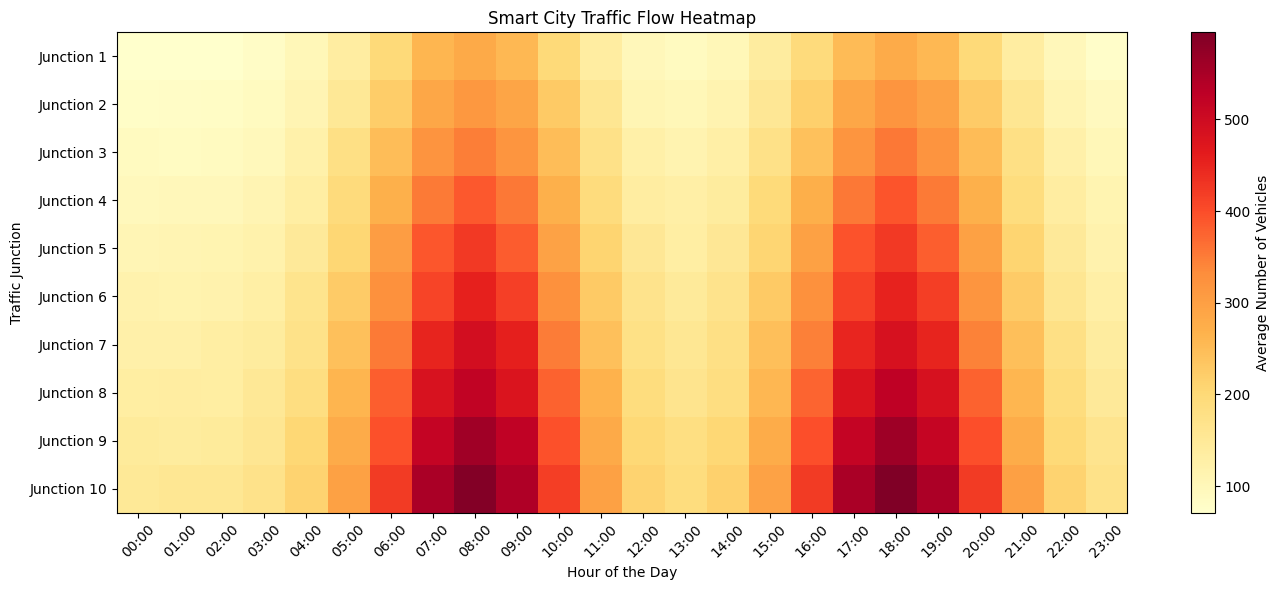

In [9]:
junction_hourly_average = traffic_data.mean(axis=0)
plt.figure(figsize=(14, 6))
plt.imshow(
    junction_hourly_average,
    aspect="auto",
    cmap="YlOrRd",
    interpolation="nearest"
)
plt.colorbar(label="Average Number of Vehicles")
plt.xticks(
    ticks=np.arange(24),
    labels=[f"{h:02d}:00" for h in hours],
    rotation=45
)
plt.yticks(
    ticks=np.arange(junctions),
    labels=[f"Junction {j + 1}" for j in range(junctions)]
)
plt.xlabel("Hour of the Day")
plt.ylabel("Traffic Junction")
plt.title("Smart City Traffic Flow Heatmap")
plt.tight_layout()
plt.show()

7. HOURLY TRAFFIC GRAPH

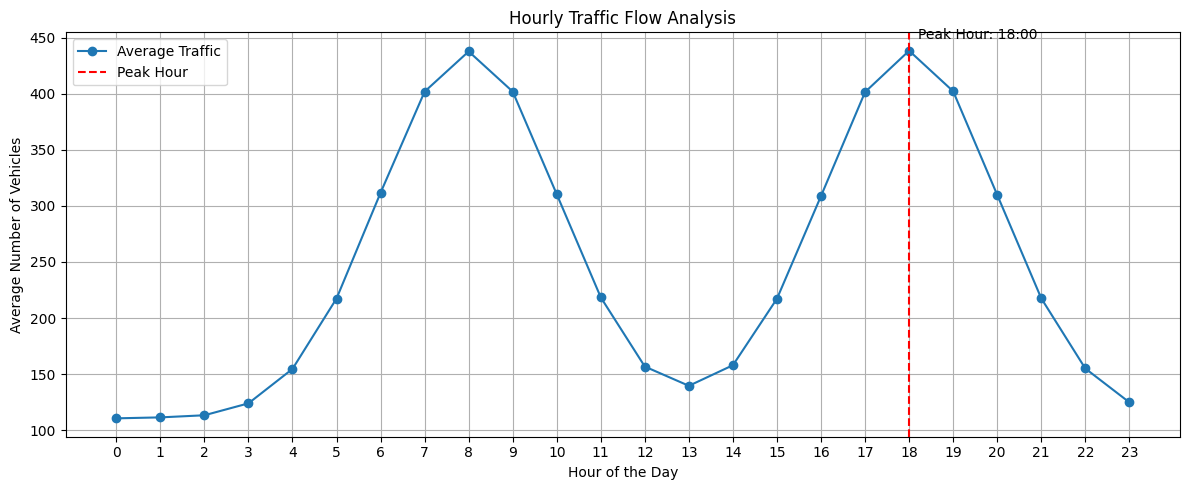

In [11]:
plt.figure(figsize=(12, 5))
plt.plot(
    hours,
    average_hourly_traffic,
    marker="o",
    label="Average Traffic"
)
plt.axvline(
    peak_hour,
    linestyle="--",
    color="red",
    label="Peak Hour"
)
plt.text(
    peak_hour + 0.2,
    average_hourly_traffic[peak_hour] + 10,
    f"Peak Hour: {peak_hour}:00"
)
plt.xlabel("Hour of the Day")
plt.ylabel("Average Number of Vehicles")
plt.title("Hourly Traffic Flow Analysis")
plt.xticks(hours)
plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

8. DAILY TRAFFIC ANALYSIS

Total vehicles across all junctions and hours per day

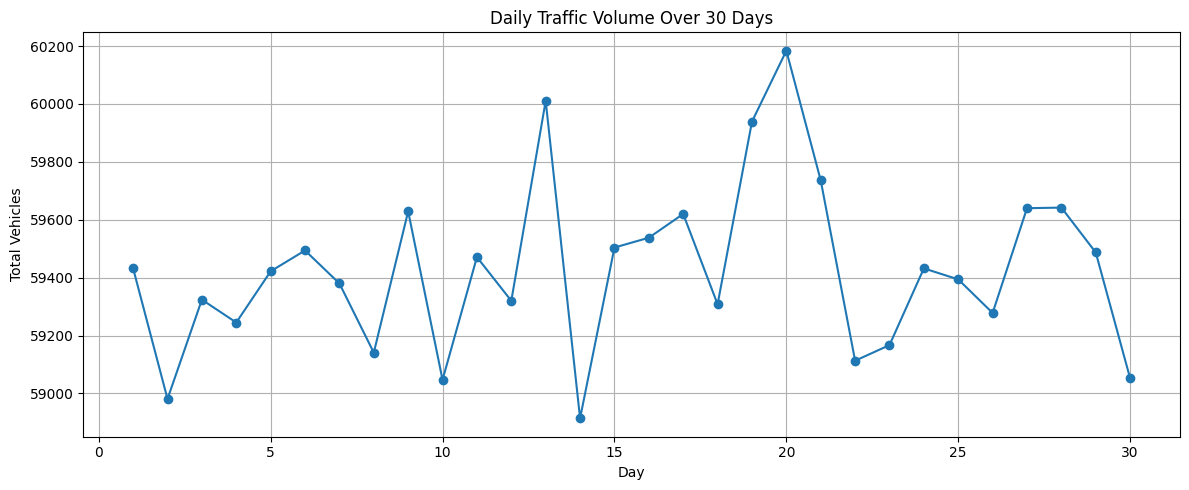


Average total vehicles per day: 59428.17


In [12]:
daily_traffic = traffic_data.sum(axis=(1, 2))
plt.figure(figsize=(12, 5))
plt.plot(
    np.arange(1, days + 1),
    daily_traffic,
    marker="o"
)
plt.xlabel("Day")
plt.ylabel("Total Vehicles")
plt.title("Daily Traffic Volume Over 30 Days")
plt.grid(True)
plt.tight_layout()
plt.show()
print("\nAverage total vehicles per day:",
      round(daily_traffic.mean(), 2))

9. COMPARE VECTORIZED AND LOOP METHODS

In [13]:
print("\nPERFORMANCE COMPARISON")
print("-" * 45)

# Vectorized calculation

start = time.perf_counter()
for _ in range(100):
    vectorized_result = traffic_data.mean(axis=(0, 1))
vectorized_time = time.perf_counter() - start

# Loop-based calculation

start = time.perf_counter()
for _ in range(100):
    loop_result = np.zeros(24)
    for h in range(24):
        loop_result[h] = traffic_data[:, :, h].mean()
loop_time = time.perf_counter() - start
print(f"Vectorized time: {vectorized_time:.6f} seconds")
print(f"Loop-based time: {loop_time:.6f} seconds")
if vectorized_time > 0:
    speedup = loop_time / vectorized_time
    print(f"Measured speedup: {speedup:.2f}x")

# Verify both approaches produce the same result

print(
    "Results match:",
    np.allclose(vectorized_result, loop_result)
)


PERFORMANCE COMPARISON
---------------------------------------------
Vectorized time: 0.007106 seconds
Loop-based time: 0.018384 seconds
Measured speedup: 2.59x
Results match: True


10. FINAL SUMMARY

In [14]:
print("\n" + "=" * 45)
print("PROJECT SUMMARY")
print("=" * 45)
print("Total days simulated:", days)
print("Total junctions:", junctions)
print("Total records:", traffic_data.size)
print("Peak traffic hour:", f"{peak_hour}:00")
print("Busiest junction:", busiest_junction + 1)
print("Average vehicles/hour:", round(traffic_data.mean(), 2))
print("\nTraffic simulation completed successfully!")


PROJECT SUMMARY
Total days simulated: 30
Total junctions: 10
Total records: 7200
Peak traffic hour: 18:00
Busiest junction: 10
Average vehicles/hour: 247.62

Traffic simulation completed successfully!
